# DuckDB

[DuckDB](https://duckdb.org) is an analytical SQL database. It runs in the
notebook with no server: it reads CSV, JSON and Parquet files over HTTP
and keeps tables in memory.

## Start the database

In the apps, cells run in a Web Worker, so DuckDB runs its WebAssembly
build in a Worker of its own. Its script comes from the jsDelivr CDN; a
small Blob script loads it, since a page can only start a Worker from its
own origin. On Node, Deno and Bun, DuckDB's native build,
`@duckdb/node-api`, runs in the kernel's process instead.

Either way, `query` runs SQL and returns the result's columns and its rows
as plain objects, and `close` frees the database.

In [1]:
type Result = { columns: { name: string; type: string }[]; rows: Record<string, unknown>[] };
let query: (sql: string) => Promise<Result>;
let close: () => Promise<void>;

if (/^(Node\.js|Deno|Bun)\//.test(navigator.userAgent)) {
  const { DuckDBInstance } = await import("npm:@duckdb/node-api@1.5.6-r.2");
  const db = await DuckDBInstance.create(":memory:");
  const conn = await db.connect();
  query = async sql => {
    const result = await conn.runAndReadAll(sql);
    const types = result.columnTypes();
    return {
      columns: result.columnNames().map((name, i) => ({ name, type: String(types[i]) })),
      rows: result.getRowObjectsJS(),
    };
  };
  close = async () => { conn.closeSync(); db.closeSync(); };
} else {
  const duckdb = await import("npm:@duckdb/duckdb-wasm@1.29.0");
  const bundle = await duckdb.selectBundle(duckdb.getJsDelivrBundles());
  const loader = URL.createObjectURL(new Blob([`importScripts("${bundle.mainWorker}");`], { type: "text/javascript" }));
  const db = new duckdb.AsyncDuckDB(new duckdb.VoidLogger(), new Worker(loader));
  await db.instantiate(bundle.mainModule, bundle.pthreadWorker);
  URL.revokeObjectURL(loader);
  const conn = await db.connect();
  query = async sql => {
    const table = await conn.query(sql);
    return {
      columns: table.schema.fields.map(f => ({ name: f.name, type: String(f.type) })),
      rows: table.toArray().map(row => row.toJSON()),
    };
  };
  close = async () => { await conn.close(); await db.terminate(); };
}
(await query("select version() as version")).rows[0];

{ version: 'v1.1.1' }

## Show a result as a table

This helper turns a result into a Markdown table, and is the cell's
result.

In [2]:
async function sql(text: string, limit = 20) {
  const { columns, rows } = await query(text);
  const show = (v: unknown, type: string) => {
    if (v === null || v === undefined) return "";
    if (v instanceof Date || /^(date|timestamp)/i.test(type)) return new Date(v instanceof Date ? v : Number(v)).toISOString().slice(0, 10);
    const n = typeof v === "bigint" ? Number(v) : v;
    if (typeof n !== "number") return String(n);
    if (!Number.isInteger(n)) return n.toFixed(2);
    return Math.abs(n) >= 10_000 ? n.toLocaleString("en-US") : String(n);
  };
  const lines = rows.slice(0, limit).map(r => `| ${columns.map(c => show(r[c.name], c.type)).join(" | ")} |`);
  const more = rows.length > limit ? `\n\n${rows.length - limit} more rows` : "";
  return jupyter.md`| ${columns.map(c => c.name).join(" | ")} |\n| ${columns.map(() => "---").join(" | ")} |\n${lines.join("\n")}${more}`;
}

await sql(`select 'Ganymede' as moon, 2634.1::double as radius_km, 1610 as discovered, date '1610-01-07' as first_seen`);

| moon | radius_km | discovered | first_seen |
| --- | --- | --- | --- |
| Ganymede | 2634.10 | 1610 | 1610-01-07 |

## Query a file over HTTP

DuckDB reads a remote CSV as a table, guessing its columns' types. Here,
four years of Seattle weather.

In [3]:
await query(`
  create table seattle as
  select * from read_csv_auto('https://raw.githubusercontent.com/vega/vega-datasets/v2.11.0/data/seattle-weather.csv')
`);
await sql(`describe seattle`);

| column_name | column_type | null | key | default | extra |
| --- | --- | --- | --- | --- | --- |
| date | DATE | YES |  |  |  |
| precipitation | DOUBLE | YES |  |  |  |
| temp_max | DOUBLE | YES |  |  |  |
| temp_min | DOUBLE | YES |  |  |  |
| wind | DOUBLE | YES |  |  |  |
| weather | VARCHAR | YES |  |  |  |

In [4]:
await sql(`
  select year(date) as year,
         round(avg(temp_max), 1) as avg_high,
         round(sum(precipitation)) as rain_mm,
         count(*) filter (where weather = 'sun') as sunny_days
  from seattle
  group by year
  order by year
`);

| year | avg_high | rain_mm | sunny_days |
| --- | --- | --- | --- |
| 2012 | 15.30 | 1226 | 118 |
| 2013 | 16.10 | 828 | 173 |
| 2014 | 17 | 1233 | 187 |
| 2015 | 17.40 | 1139 | 162 |

Parquet is read in ranges, so a query fetches only the columns and row
groups it needs. This file holds every New York yellow cab trip of April
2019, 127 MB, but the query below reads two of its columns.

In [5]:
const taxi = "https://blobs.duckdb.org/data/taxi_2019_04.parquet";
await sql(`
  select passenger_count as passengers, count(*) as trips
  from '${taxi}'
  where passenger_count between 1 and 6
  group by passengers
  order by passengers
`);

| passengers | trips |
| --- | --- |
| 1 | 5,210,818 |
| 2 | 1,113,704 |
| 3 | 317,979 |
| 4 | 153,369 |
| 5 | 313,982 |
| 6 | 186,408 |

## Data from a cell

Data the notebook already has goes in as JSON, read by DuckDB's
`from_json` and spread into columns by `unnest`. Here, the strongest
earthquakes of the past week, from the US Geological Survey.

In [6]:
const feed = await (await fetch("https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_week.geojson")).json();
const quakes = feed.features.map((f: any) => ({
  magnitude: f.properties.mag,
  place: f.properties.place,
  depth_km: f.geometry.coordinates[2],
}));
const json = JSON.stringify(quakes).replaceAll("'", "''");
await query(`
  create table quakes as
  select unnest(from_json('${json}', '[{"magnitude": "DOUBLE", "place": "VARCHAR", "depth_km": "DOUBLE"}]'), recursive := true)
`);
await sql(`
  select case when depth_km < 70 then 'shallow' when depth_km < 300 then 'intermediate' else 'deep' end as depth,
         count(*) as quakes,
         max(magnitude) as strongest
  from quakes
  group by depth
  order by min(depth_km)
`);

| depth | quakes | strongest |
| --- | --- | --- |
| shallow | 77 | 6.40 |
| intermediate | 23 | 5.40 |
| deep | 6 | 5.10 |

## Results into charts

A query's rows are plain objects too. Monthly rain as bars, straight from
SQL into SVG:

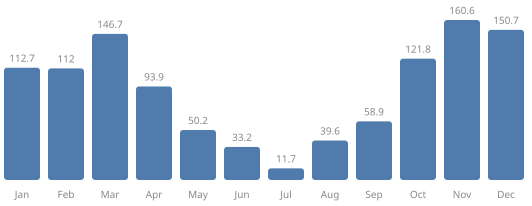

In [7]:
const months = (await query(`
  select month(date) as m, round(avg(precipitation) * 30, 1) as rain
  from seattle group by m order by m
`)).rows.map(r => ({ m: Number(r.m), rain: Number(r.rain) }));
const max = Math.max(...months.map(d => d.rain));
const names = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split(" ");
const bars = months.map((d, i) => {
  const h = (d.rain / max) * 160;
  return `<rect x="${i * 44 + 4}" y="${180 - h}" width="36" height="${h}" rx="3" fill="#4f7cac"/>
    <text x="${i * 44 + 22}" y="198" text-anchor="middle">${names[d.m - 1]}</text>
    <text x="${i * 44 + 22}" y="${174 - h}" text-anchor="middle">${d.rain}</text>`;
});
jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="532" height="206" font-family="system-ui" font-size="10" fill="#888">${bars.join("")}</svg>`;

## Clean up

Closing the database frees its memory. Restarting the kernel does the
same.

In [8]:
await close();